# Hand gesture preprocessing

Three classes: **thumbs_up**, **thumbs_down**, **stop**.

`dataset` contains 28 personal originals, `augmented` contains 197 existing variants, and `external` contains 225 internet photographs. Each class has 75 personal images including variants and 75 external images.

The main correction is to crop the hand before resizing. External images previously showed entire people; shrinking those scenes made the thumb too small. This notebook demonstrates the exact preprocessing used for the saved models. Original files are never overwritten.


In [ ]:
%pip install numpy pandas pillow matplotlib


## 1. Paths and image counts

Run cells from top to bottom. The two notebooks work from either the project folder or its notebooks subfolder.


In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "dataset").is_dir():
    ROOT = ROOT.parent
classes = ["thumbs_up", "thumbs_down", "stop"]
IMG_SIZE = 128
SEED = 42
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
assert (ROOT / "dataset").is_dir(), "Open the notebook inside the project folder"

NOTEBOOK_NAME = "01_preprocessing.ipynb"
# Box coordinates are stored inside this notebook, so no extra annotation folder is needed.
notebook_path = ROOT / "notebooks" / NOTEBOOK_NAME
crop_metadata = json.loads(notebook_path.read_text(encoding="utf-8-sig"))["metadata"]["gesture_project"]
hand_boxes = crop_metadata["hand_boxes"]
CROP_MARGIN = crop_metadata["crop_margin"]


In [2]:
counts = pd.DataFrame({
    folder: [sum(p.is_file() and p.suffix.lower() in VALID_EXT
                 for p in (ROOT / folder / label).iterdir()) for label in classes]
    for folder in ["dataset", "augmented", "external"]}, index=classes)
display(counts)
print("Total images:", int(counts.sum().sum()))
print("Personal originals plus variants:", int(counts[["dataset", "augmented"]].sum().sum()))


Total images: 450
Personal originals plus variants: 225


,dataset,augmented,external
thumbs_up,9,66,75
thumbs_down,7,68,75
stop,12,63,75


## 2. Crop the hand

Internet hand boxes come from the original HaGRID annotations. Personal originals were manually annotated; the matching boxes for existing augmented copies were obtained by matching them to their originals. Coordinates are stored in notebook metadata, indexed by image path.

The crop is square with 18% context on each side of the longest hand dimension. It is then resized to 128 × 128. No gesture labels are added or changed.

This project evaluates **classification of annotated hand crops**. It does not evaluate automatic hand detection in arbitrary full-frame photographs. A new photograph needs a hand box or should already be cropped around one hand.


In [3]:
def crop_hand(image, box):
    x, y, width, height = box
    image_width, image_height = image.size
    x, y = x * image_width, y * image_height
    width, height = width * image_width, height * image_height
    side = max(width, height) * (1 + 2 * CROP_MARGIN)
    center_x, center_y = x + width / 2, y + height / 2
    return image.crop((int(center_x - side / 2), int(center_y - side / 2),
                       int(center_x + side / 2), int(center_y + side / 2)))

def read_hand(path):
    relative_path = path.relative_to(ROOT).as_posix()
    assert relative_path in hand_boxes, f"Add a hand box for the new image: {relative_path}"
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        cropped = crop_hand(image, hand_boxes[relative_path])
        return ImageOps.pad(cropped, (IMG_SIZE, IMG_SIZE))


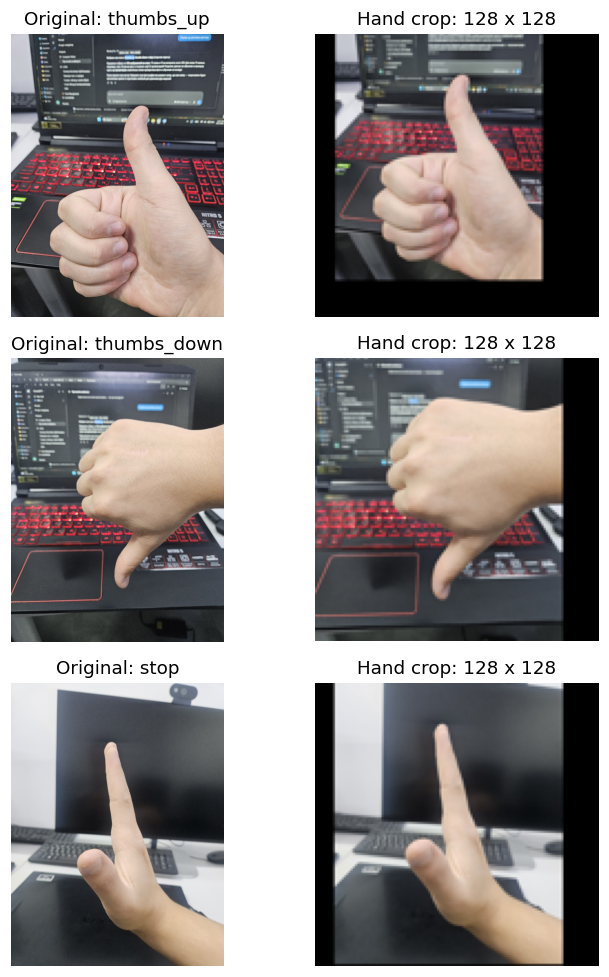

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(7, 9))
for row, label in enumerate(classes):
    path = sorted((ROOT / "dataset" / label).glob("*.jpg"))[0]
    with Image.open(path) as image:
        axes[row, 0].imshow(ImageOps.exif_transpose(image).convert("RGB"))
    axes[row, 0].set_title(f"Original: {label}")
    axes[row, 1].imshow(read_hand(path))
    axes[row, 1].set_title("Hand crop: 128 x 128")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()


## 3. Existing augmentation and normalization

Previously saved variants are documented as using mild rotation, horizontal reflection, brightness, contrast, saturation, scale changes and occasional blur. Exact random parameters for each stored variant were not retained. Their saved files remain intact and are included in training. Original and augmented members of each family stay in training only. Current online training transformations are defined explicitly in notebook 02.

Pixels are divided by 255 for [0, 1]. MobileNetV2 additionally rescales [0, 1] to [-1, 1] inside the model. Never flip vertically: it can swap thumbs_up and thumbs_down.


Shape: (128, 128, 3) Range: 0.0 1.0


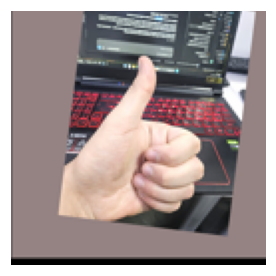

In [5]:
path = sorted((ROOT / "augmented/thumbs_up").glob("*.jpg"))[0]
image = read_hand(path)
pixels = np.asarray(image, dtype=np.float32) / 255.0
print("Shape:", pixels.shape, "Range:", float(pixels.min()), float(pixels.max()))
plt.figure(figsize=(3, 3))
plt.imshow(pixels)
plt.axis("off")
plt.show()


## 4. A small augmentation example

This demonstration changes a crop in memory. It does not create extra files or change the saved dataset.


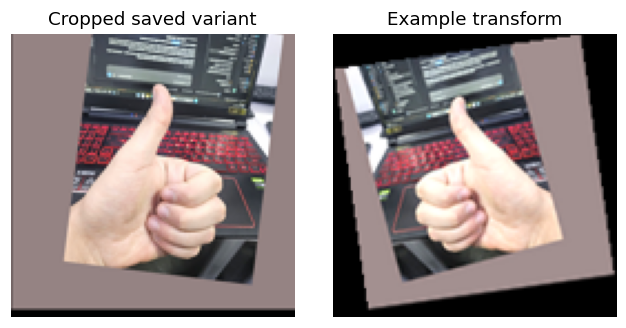

In [6]:
from PIL import ImageEnhance, ImageFilter
def augment(image):
    image = ImageOps.mirror(image)
    image = image.rotate(8, resample=Image.Resampling.BICUBIC, expand=True)
    image = ImageEnhance.Brightness(image).enhance(1.1)
    return ImageOps.pad(image.filter(ImageFilter.GaussianBlur(0.2)), (IMG_SIZE, IMG_SIZE))

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(image)
axes[0].set_title("Cropped saved variant")
axes[1].imshow(augment(image))
axes[1].set_title("Example transform")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## Next

Open `02_gesture_project.ipynb`. Its default mode loads the three saved trained models and displays their results. Enable `RUN_TRAINING` only when intentionally retraining. Dataset diversity remains limited: 197 variants come from 28 personal originals.
